# Tugas PBL JS15 - Prediksi Sleep Disorder

Pipeline machine learning menggunakan dataset lokal `Dataset/Sleep_health_and_lifestyle_dataset.csv`.

In [1]:
from pathlib import Path
import pickle

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

dataset_candidates = [
    Path("../Dataset/Sleep_health_and_lifestyle_dataset.csv"),
    Path("Dataset/Sleep_health_and_lifestyle_dataset.csv"),
]
dataset_path = next(path for path in dataset_candidates if path.exists())
df = pd.read_csv(dataset_path)
df.head()

,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,NaN
1,2,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
2,3,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea


In [2]:
# Nilai "None" dibaca pandas sebagai NaN, sehingga dikembalikan sebagai kelas target.
df["Sleep Disorder"] = df["Sleep Disorder"].fillna("None")
# Memisahkan tekanan darah menjadi fitur sistolik dan diastolik.
blood_pressure = df["Blood Pressure"].str.split("/", expand=True).astype(float)
df["Systolic BP"] = blood_pressure[0]
df["Diastolic BP"] = blood_pressure[1]
df = df.drop(columns=["Person ID", "Blood Pressure"])
df.info()
df["Sleep Disorder"].value_counts()

<class 'pandas.DataFrame'>
RangeIndex: 374 entries, 0 to 373
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Gender                   374 non-null    str    
 1   Age                      374 non-null    int64  
 2   Occupation               374 non-null    str    
 3   Sleep Duration           374 non-null    float64
 4   Quality of Sleep         374 non-null    int64  
 5   Physical Activity Level  374 non-null    int64  
 6   Stress Level             374 non-null    int64  
 7   BMI Category             374 non-null    str    
 8   Heart Rate               374 non-null    int64  
 9   Daily Steps              374 non-null    int64  
 10  Sleep Disorder           374 non-null    str    
 11  Systolic BP              374 non-null    float64
 12  Diastolic BP             374 non-null    float64
dtypes: float64(3), int64(6), str(4)
memory usage: 38.1 KB


Sleep Disorder
None           219
Sleep Apnea     78
Insomnia        77
Name: count, dtype: int64

In [3]:
target = "Sleep Disorder"
X = df.drop(columns=target)
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = [col for col in X.columns if col not in numeric_features]
preprocessor = ColumnTransformer([
    ("numeric", "passthrough", numeric_features),
    ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300, class_weight="balanced", random_state=42
    )),
])
model.fit(X_train, y_train)
print("Model berhasil dilatih.")

Model berhasil dilatih.


Akurasi testing: 86.67%
              precision    recall  f1-score   support

    Insomnia       0.70      0.93      0.80        15
        None       1.00      0.86      0.93        44
 Sleep Apnea       0.76      0.81      0.79        16

    accuracy                           0.87        75
   macro avg       0.82      0.87      0.84        75
weighted avg       0.89      0.87      0.87        75



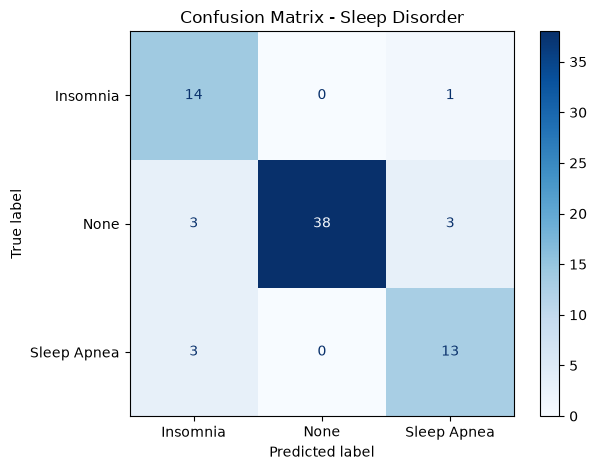

In [4]:
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print(f"Akurasi testing: {accuracy:.2%}")
print(classification_report(y_test, y_pred, zero_division=0))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues")
plt.title("Confusion Matrix - Sleep Disorder")
plt.tight_layout()
plt.show()

In [5]:
output_path = Path("sleep_disorder_model.pkl")
with output_path.open("wb") as model_file:
    pickle.dump(model, model_file)
print(f"Model disimpan di: {output_path.resolve()}")

Model disimpan di: C:\ListPc\244107020089_MachineLearning\JS15PBL\sleep_disorder_model.pkl
